# Influence function and sensitivity curve

This program shows the influence function of different statistics. For now, it is just possible to choose between mean, variance, or some quantile. The samples are simulated considering a Normal distribution with mean `MEAN` and standard deviation `STD`, each sample is of size `N`, and a total of `SAMPLES` samples is simulated. Together with the influence function, the sensitivity curve is calculated for each sample. Since this curve is a random variable by itself, we calculate a pointwise interval for it using the quantiles of the simulated curves: at each point, the interval contains a proportion `1-ALPHA` of the curves.

The influence function of a statistic $T$ at the distribution $F$ measures the effect on $T$ of a small contamination at the point $x$,

$$
IF(x)=\lim_{\varepsilon\to 0}\frac{T\big((1-\varepsilon)F+\varepsilon\delta_x\big)-T(F)}{\varepsilon},
$$

where $\delta_x$ is the distribution with all its mass at $x$. A statistic with a bounded influence function is robust: one observation, however extreme, changes it by a limited amount.

---

The sensitivity curve is the version of the influence function for a sample. It is the change of the statistic when the observation $x$ is added to the sample $x_1,\ldots,x_n$, multiplied by the new sample size,

$$SC_n(x)=(n+1)\Big[T_{n+1}(x_1,\ldots,x_n,x)-T_n(x_1,\ldots,x_n)\Big]$$

---

The influence function for the mean is given by

$$x-\mu$$

---

The influence function for the variance is given by

$$(x-\mu)^2-\sigma^2$$

---

The influence function for the quantile of probability $p$, $Q_p$, is given by

$$\frac{p-1_{x\leq Q_p}}{f(Q_p)}$$

where $f$ is the density of $F$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import norm
from matplotlib.lines import Line2D
from ipywidgets import interact, Dropdown, SelectionSlider

In [2]:
N = 10**3 #Sample size
SAMPLES = 1000 #Number of simulations

MEAN = 2
STD = 1

ALPHA = 0.5

SEED = 0 #Seed of the random number generator

In [3]:
# Colors shared by all the plots
line_color  = '#1f4e79'
ci_color    = '#7fb8d8'
opt_color   = '#E69F00'

## The class

In [4]:
class InfluenceFunction:
    def __init__(self, SampleSize=N, NumberSamples=SAMPLES, Mean=MEAN, Std=STD, Functional='mean', P=None, Seed=SEED):
        # Possible values for Functional: mean, quantile, variance
        if Functional=='quantile' and P is None:
            raise ValueError("Value of P must be passed if Functional is quantile")

        self.n = SampleSize
        self.numbersamples = NumberSamples

        self.mean = Mean
        self.std = Std
        self.xvector = np.linspace(Mean-3*Std, Mean+3*Std, 100)

        self.functional = Functional
        self.name = Functional.capitalize()
        if Functional == 'quantile':
            self.p = P
            self.quantile = norm.ppf(self.p, Mean, Std)
            self.name = f'Quantile of probability {P}'

        self.rng = np.random.default_rng(Seed)

    def Statistic(self, sample):
        if self.functional == 'mean':
            return np.mean(sample)
        elif self.functional == 'variance':
            return np.var(sample)
        else:
            return np.quantile(sample, self.p)

    def SensitivityCurve(self, x, sample):
        return (self.n+1) * (self.Statistic(np.append(sample, x)) - self.Statistic(sample))

    def InfluenceFunction(self, x):
        if self.functional == 'mean':
            return x - self.mean
        elif self.functional == 'variance':
            return (x-self.mean)**2 - self.std**2
        else:
            if x <= self.quantile:
                return (self.p - 1) / norm.pdf(self.quantile, self.mean, self.std)
            else:
                return self.p / norm.pdf(self.quantile, self.mean, self.std)

    def CalculateEstimates(self):
        Estimate = []
        for b in range(self.numbersamples):
            Sample = self.rng.normal(self.mean, self.std, size=self.n)
            Estimate.append([self.SensitivityCurve(x, Sample) for x in self.xvector])

        self.estimate = np.array(Estimate)
        self.influence = [self.InfluenceFunction(x) for x in self.xvector]

    def PlotReference(self, ax):
        # Average of the sensitivity curves and influence function
        ax.plot(self.xvector, self.estimate.mean(axis=0), color=line_color, lw=2, label='Average of the sensitivity curves')
        ax.plot(self.xvector, self.influence, linestyle='--', color=opt_color, lw=2.5, label='Influence function')
        ax.axhline(0, color='k', lw=0.8, alpha=0.5)

        ax.set_xlabel('x (observation added to the sample)')
        ax.grid(True, alpha=0.25)

    def PlotAll(self, ax):
        for b in range(self.numbersamples):
            ax.plot(self.xvector, self.estimate[b], alpha=0.1, color=ci_color, lw=1)
        self.PlotReference(ax)

        ax.set_ylabel('Sensitivity curve')
        ax.set_title(f'{self.numbersamples} sensitivity curves, one for each sample')

    def PlotInterval(self, ax, alpha = ALPHA):
        ax.fill_between(
            self.xvector,
            np.quantile(self.estimate, alpha/2, axis=0),
            np.quantile(self.estimate, 1-alpha/2, axis=0),
            color=ci_color,
            alpha=0.7
        )
        self.PlotReference(ax)

        ax.set_title(f'Central {1-alpha:.0%} of the sensitivity curves at each x')

    def main(self, alpha=ALPHA):
        self.CalculateEstimates()

        fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

        self.PlotAll(axes[0])
        self.PlotInterval(axes[1], alpha)

        handles, labels = axes[1].get_legend_handles_labels()
        handles = [Line2D([], [], color=ci_color, lw=2), plt.Rectangle((0, 0), 1, 1, color=ci_color, alpha=0.7)] + handles
        labels = ['Sensitivity curve of one sample', f'Central {1-alpha:.0%} of the curves'] + labels
        fig.legend(handles, labels, loc='lower center', ncol=len(labels), frameon=False)
        fig.suptitle(f'{self.name}, n = {self.n}', fontsize=14)
        plt.tight_layout(rect=(0, 0.06, 1, 1))

## Mean

The sensitivity curve of the mean does not depend on $n$: adding the observation $x$ gives $SC_n(x)=x-\bar x_n$, a line with slope one that only moves up and down with the mean of the sample. The influence function is not bounded, a single extreme observation can take the mean anywhere.

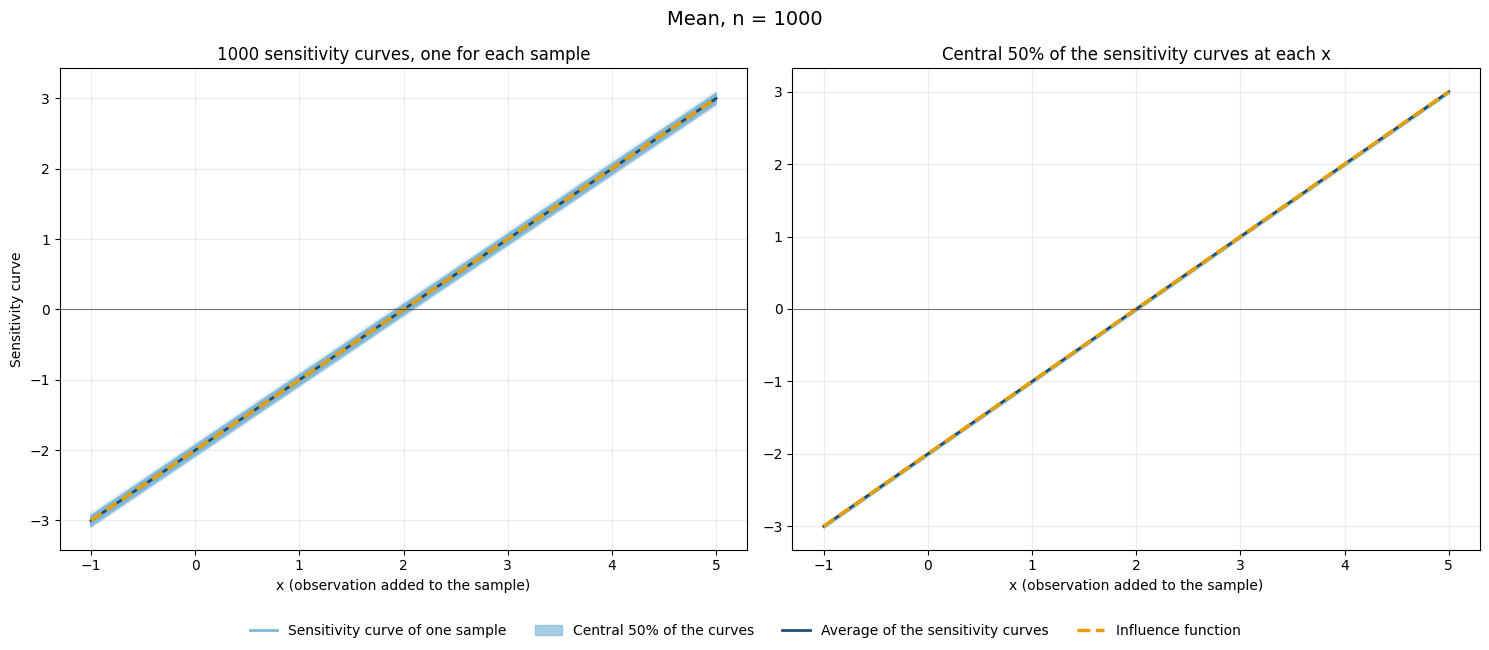

In [5]:
InfluenceFunction().main()

## Variance

The influence function of the variance is a parabola, also not bounded, and it grows faster than that of the mean. It is negative for $|x-\mu|<\sigma$: an observation close to the center makes the variance smaller.

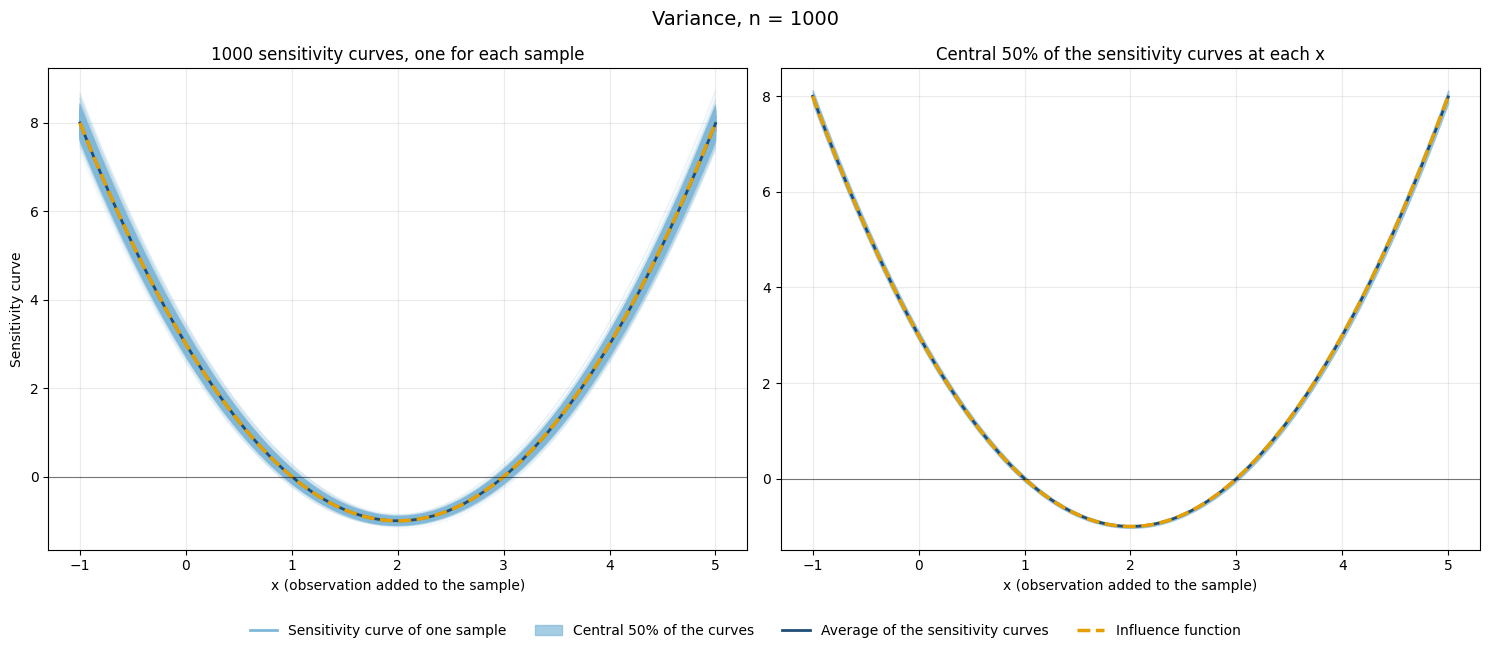

In [6]:
InfluenceFunction(Functional='variance').main()

## Quantiles

The influence function of a quantile takes only two values, so it is bounded: it matters on which side of the quantile the new observation falls, not how far it is. This is the reason why the median is robust. The sensitivity curves vary much more from sample to sample than those of the mean and the variance, because they depend on the distance between the observations next to the quantile.

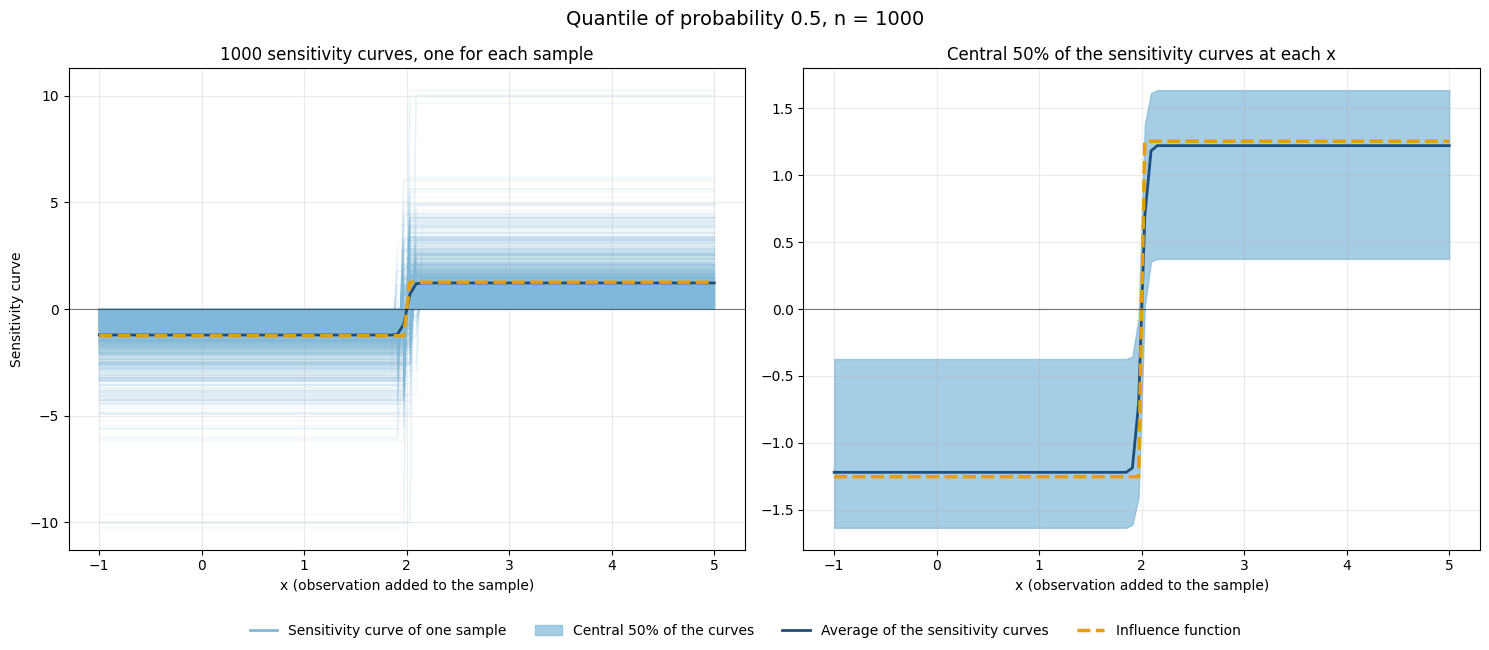

In [7]:
InfluenceFunction(Functional='quantile', P=0.5).main()

For the quantile of probability 0.9 the two values are not symmetric: an observation above the quantile moves it up nine times more than an observation below moves it down.

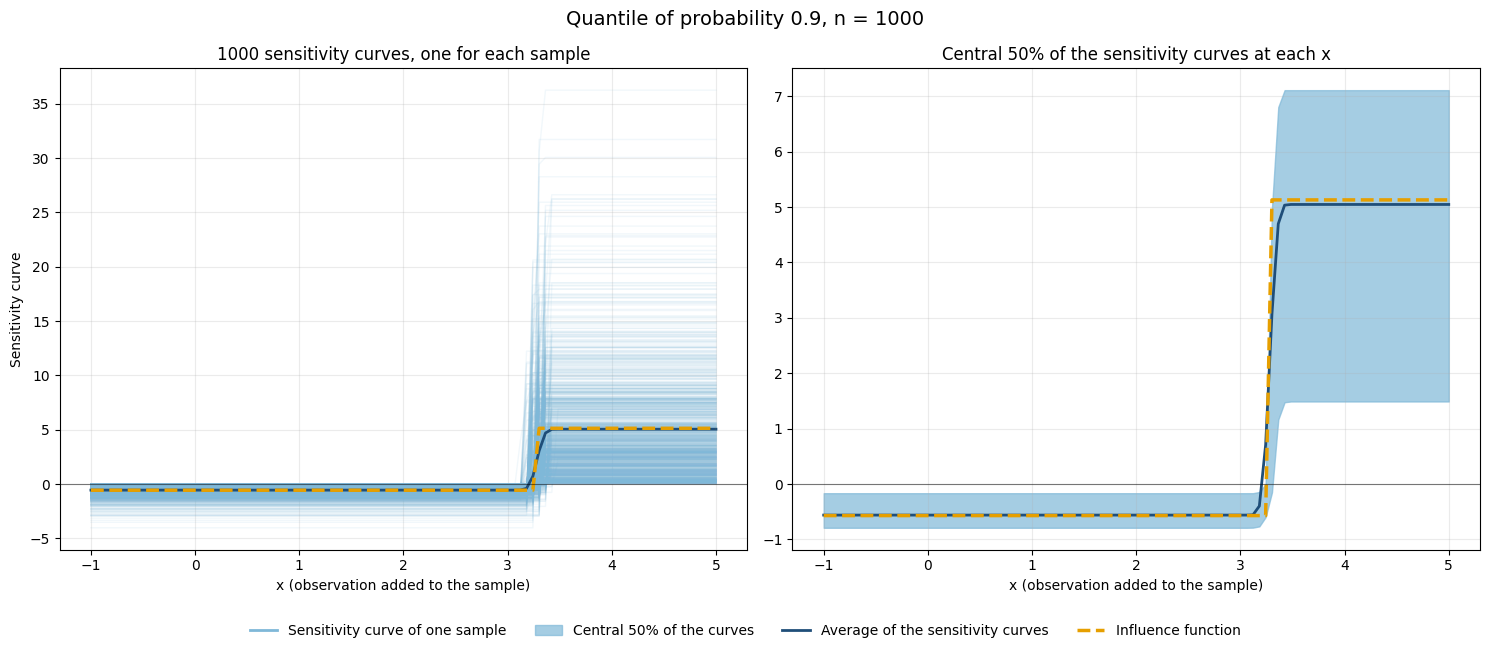

In [8]:
InfluenceFunction(Functional='quantile', P=0.9).main()

## The effect of the sample size

Choose the statistic and the sample size (the quantile is the median, $p=0.5$). To keep it fast, 200 samples are simulated.

- Mean: the sample size does not matter, the curve is always $x-ar x_n$.
- Variance: the curves get closer to the influence function as $n$ grows.
- Median: the average of the curves gets closer to the influence function and the jump gets sharper, but the band does not get narrower. The height of the step is $n+1$ times half the distance between the two central observations, and this product does not converge to a constant: it stays random, with mean close to $
rac{1}{2f(Q_{0.5})}$, however large the sample is.

In [9]:
def InteractiveSensitivity(Functional, n):
    P = 0.5 if Functional == 'quantile' else None
    InfluenceFunction(SampleSize=n, NumberSamples=200, Functional=Functional, P=P).main()
    plt.show()

interact(InteractiveSensitivity,
         Functional=Dropdown(options=['mean', 'variance', 'quantile'], value='quantile', description='Statistic'),
         n=SelectionSlider(options=[10, 30, 100, 300, 1000], value=30, description='n'));

interactive(children=(Dropdown(description='Statistic', index=2, options=('mean', 'variance', 'quantile'), val…

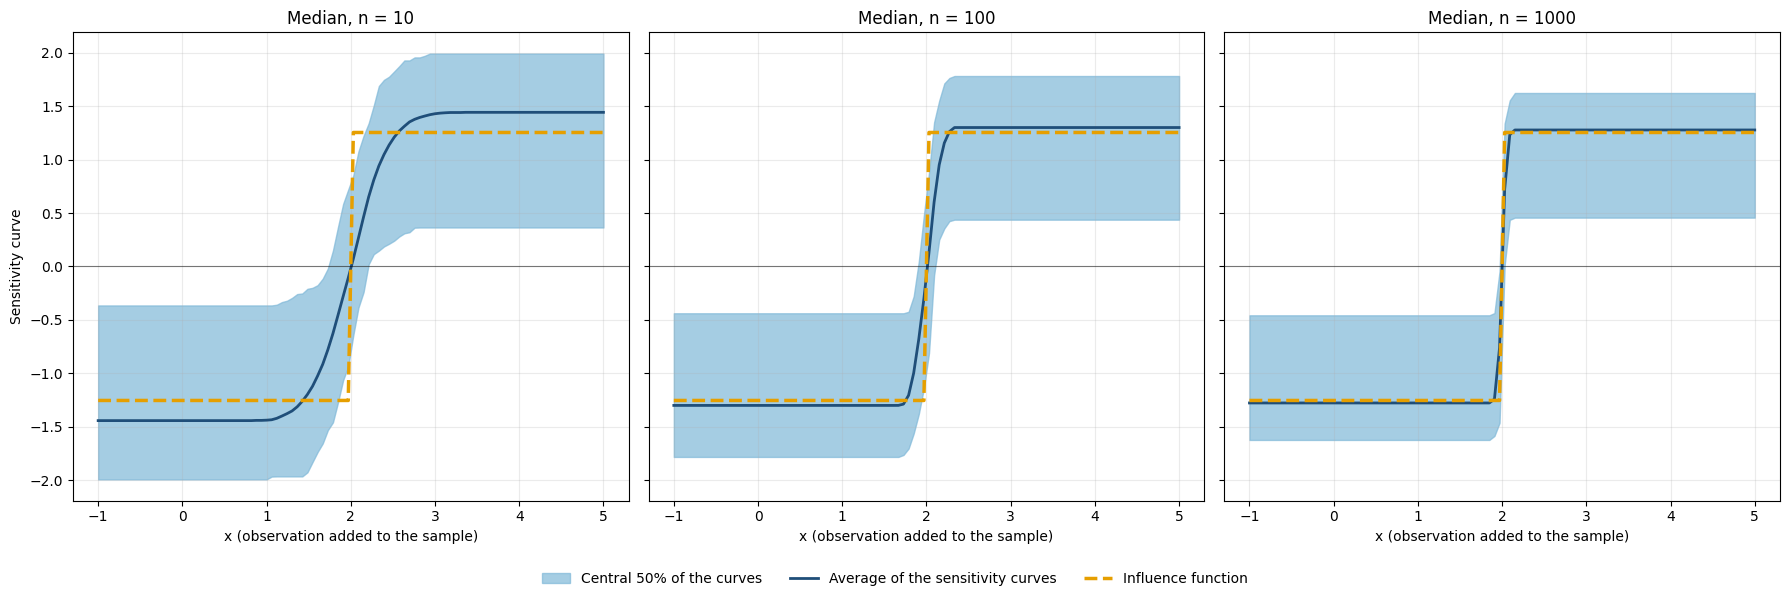

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for ax, n in zip(axes, [10, 100, 1000]):
    Median = InfluenceFunction(SampleSize=n, NumberSamples=200, Functional='quantile', P=0.5)
    Median.CalculateEstimates()
    Median.PlotInterval(ax)
    ax.set_title(f'Median, n = {n}')
axes[0].set_ylabel('Sensitivity curve')

handles, labels = axes[0].get_legend_handles_labels()
handles = [plt.Rectangle((0, 0), 1, 1, color=ci_color, alpha=0.7)] + handles
labels = [f'Central {1-ALPHA:.0%} of the curves'] + labels
fig.legend(handles, labels, loc='lower center', ncol=len(labels), frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1))